# Validate `T0.1MeV_nBatN3n0_aQstar0.35_B180`

This notebook loads the serialized output dict produced by `RMFsolver.phase_velocity.solve_steady_front_entropy_TQguess_uagrad(..., return_profile=True)` and checks whether the saved profile satisfies

\[
\partial_x(u n_B)=0,\qquad
\partial_x(h u^2 + P)=0,
\]
\[
\partial_x(D_K \partial_x a - u a)=R(a),\qquad
\partial_x(su)=-\frac{n_B^Q}{T}\mu_K\,\partial_x(u a).
\]

The notebook now targets `T0.1MeV_nBatN3n0_aQstar0.35_B180.npz`. That file stores the solver result as a wrapped object array inside the archive, so the loader below unwraps that format automatically.

In [1]:
from pathlib import Path
import os
import warnings

REPO = Path.cwd()
CACHE = REPO / ".mpl-cache"
CACHE.mkdir(exist_ok=True)

os.environ.setdefault("MPLCONFIGDIR", str(CACHE))
os.environ.setdefault("XDG_CACHE_HOME", str(CACHE))

warnings.filterwarnings("ignore", message="IProgress not found")

import numpy as np
import matplotlib.pyplot as plt

import RMFsolver.constants as const
import RMFsolver.phase_velocity as pv

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

FILE_STEM = "T0.1MeV_nBatN3n0_aQstar0.35_B180"
CANDIDATES = [
    REPO / f"{FILE_STEM}.npz",
    REPO / f"{FILE_STEM}.npz.npy",
    REPO / FILE_STEM,
]

T_INPUT = 0.1
A_QSTAR = 0.35
BAG_ONE_FORTH = 180.0
MS = 0.0
n0 = 0.16 * const.MeV_fm**3
nB_N_INPUT = 3.0 * n0
MEV_INV_TO_UM = 1.973269804e-7
RUN_FRESH_SOLVE = False

In [2]:
def load_saved_result(candidates):
    existing = [path for path in candidates if path.exists()]
    if not existing:
        raise FileNotFoundError(
            "Could not find any of: " + ", ".join(str(path.name) for path in candidates)
        )

    path = existing[0]
    raw = np.load(path, allow_pickle=True)

    if hasattr(raw, "files"):
        if len(raw.files) == 1:
            single = raw[raw.files[0]]
            if isinstance(single, np.ndarray) and single.shape == () and single.dtype == object:
                result = single.item()
            else:
                result = {key: raw[key] for key in raw.files}
        else:
            result = {key: raw[key] for key in raw.files}
    else:
        result = raw.item()

    if not isinstance(result, dict):
        raise TypeError(f"Expected the saved object to be a dict, got {type(result).__name__}")
    return path, result


def grad_on_x(values, x):
    return np.gradient(np.asarray(values, float), np.asarray(x, float), edge_order=2)


def rel_diff(lhs, rhs):
    lhs = np.asarray(lhs, float)
    rhs = np.asarray(rhs, float)
    scale = np.maximum.reduce(
        [np.abs(lhs), np.abs(rhs), np.full_like(lhs, np.finfo(float).tiny)]
    )
    return (lhs - rhs) / scale


saved_path, saved = load_saved_result(CANDIDATES)
if not bool(saved.get("success", False)):
    raise RuntimeError(f"Saved profile did not converge: {saved.get('message')}")

x = np.asarray(saved["x"], float)
s_coord = np.asarray(saved["s_coord"], float)
a = np.asarray(saved["a"], float)
q = np.asarray(saved["q"], float)
w = np.asarray(saved["w"], float)
u = np.asarray(saved["u"], float)
nB = np.asarray(saved["nB"], float)
muB = np.asarray(saved["muB"], float)
muK = np.asarray(saved["muK"], float)
T_profile = np.asarray(saved["T_profile"], float)
s_profile = np.asarray(saved["s_profile"], float)
D_profile = np.asarray(saved["D_profile"], float)
eta_profile = np.asarray(saved["eta_profile"], float)
gamma_profile = np.asarray(saved["gamma_profile"], float)

thermo = [
    pv._quark_thermo_state(
        float(muB_i),
        float(muK_i),
        BAG_ONE_FORTH,
        float(T_i),
        float(saved["jB"]),
        ms=MS,
    )
    for muB_i, muK_i, T_i in zip(muB, muK, T_profile)
]

P = np.array([state["P"] for state in thermo])
e = np.array([state["e"] for state in thermo])
h = np.array([state["h"] for state in thermo])
s_eos = np.array([state["s"] for state in thermo])

ua = u * a
mass_flux = u * nB
momentum_flux = h * u**2 + P

a_x = grad_on_x(a, x)
q_x = grad_on_x(q, x)
w_x = grad_on_x(w, x)
ua_x = grad_on_x(ua, x)

q_from_profile = D_profile * a_x - ua
reaction = gamma_profile * (a**3 + eta_profile * a)
entropy_rhs = -(saved["nB_Q"] / T_profile) * muK * ua_x

mass_residual = mass_flux - saved["jB"]
momentum_residual = momentum_flux - saved["Pi"]
eq3_residual = q_x - reaction
eq4_residual = w_x - entropy_rhs

mass_rel = mass_residual / max(abs(saved["jB"]), np.finfo(float).tiny)
momentum_rel = momentum_residual / max(abs(saved["Pi"]), np.finfo(float).tiny)
q_closure_rel = rel_diff(q_from_profile, q)
w_closure_rel = rel_diff(s_profile * u, w)
s_eos_rel = rel_diff(s_eos, s_profile)

interior = slice(1, -1)

x_end_um = x[-1] * MEV_INV_TO_UM
if x_end_um >= 0.1:
    x_plot = x * MEV_INV_TO_UM
    x_plot_label = "x [um]"
else:
    x_plot = x * MEV_INV_TO_UM * 1.0e3
    x_plot_label = "x [nm]"
x_mid_plot = x_plot[interior]

eq3_local_scale = np.maximum.reduce(
    [
        np.abs(q_x[interior]),
        np.abs(reaction[interior]),
        np.full_like(q_x[interior], np.finfo(float).tiny),
    ]
)
eq4_local_scale = np.maximum.reduce(
    [
        np.abs(w_x[interior]),
        np.abs(entropy_rhs[interior]),
        np.full_like(w_x[interior], np.finfo(float).tiny),
    ]
)
eq3_global_scale = max(
    np.max(np.abs(q_x[interior])),
    np.max(np.abs(reaction[interior])),
    np.finfo(float).tiny,
)
eq4_global_scale = max(
    np.max(np.abs(w_x[interior])),
    np.max(np.abs(entropy_rhs[interior])),
    np.finfo(float).tiny,
)

print(f"Loaded {saved_path.name}")
print(
    f"success={saved['success']}, equation mode={saved['entropy_flux_equation']}, "
    f"nodes={saved['bvp_nodes']}, niter={saved['bvp_niter']}"
)
print(
    f"jB={saved['jB']:.10f}, T_Q={saved['T_Q']:.10f}, x_end={x[-1]:.6e} MeV^-1"
)
print(
    f"tail residuals = ({saved['tail_residual_norm']:.3e}, "
    f"{saved['entropy_tail_residual_norm']:.3e})"
)
print("Derivative-based summaries below exclude the first and last grid point.")

Loaded T0.1MeV_nBatN3n0_aQstar0.35_B180.npz
success=True, equation mode=ua_gradient, nodes=248, niter=3
jB=1.2175530682, T_Q=20.2423718524, x_end=1.258232e+07 MeV^-1
tail residuals = (-5.144e-10, 6.695e-11)
Derivative-based summaries below exclude the first and last grid point.


In [3]:
summary_rows = [
    ("max |u n_B - j_B| / |j_B|", np.max(np.abs(mass_rel))),
    ("max |h u^2 + P - Pi| / |Pi|", np.max(np.abs(momentum_rel))),
    ("max interior |q - (D a_x - u a)| / local scale", np.max(np.abs(q_closure_rel[interior]))),
    ("95th pct interior |q - (D a_x - u a)| / local scale", np.percentile(np.abs(q_closure_rel[interior]), 95)),
    ("max |s u - w| / local scale", np.max(np.abs(w_closure_rel))),
    ("max |s_EOS - s_saved| / local scale", np.max(np.abs(s_eos_rel))),
    ("max interior |q_x - R(a)| / global eq3 scale", np.max(np.abs(eq3_residual[interior])) / eq3_global_scale),
    ("rms interior |q_x - R(a)| / global eq3 scale", np.sqrt(np.mean(eq3_residual[interior] ** 2)) / eq3_global_scale),
    ("95th pct interior |q_x - R(a)| / local scale", np.percentile(np.abs(eq3_residual[interior]) / eq3_local_scale, 95)),
    ("max interior |w_x + (n_B^Q/T) mu_K (u a)_x| / global eq4 scale", np.max(np.abs(eq4_residual[interior])) / eq4_global_scale),
    ("rms interior |w_x + (n_B^Q/T) mu_K (u a)_x| / global eq4 scale", np.sqrt(np.mean(eq4_residual[interior] ** 2)) / eq4_global_scale),
    ("95th pct interior |w_x + (n_B^Q/T) mu_K (u a)_x| / local scale", np.percentile(np.abs(eq4_residual[interior]) / eq4_local_scale, 95)),
]

for label, value in summary_rows:
    print(f"{label:<74} {value: .6e}")

print()
print(
    "Interpretation: the saved profile is mass- and momentum-conserving to machine precision, "
    "while the diffusion-reaction and entropy equations are satisfied to small finite-difference "
    "residuals on the reconstructed x-grid."
)

max |u n_B - j_B| / |j_B|                                                   0.000000e+00
max |h u^2 + P - Pi| / |Pi|                                                 8.945344e-13
max interior |q - (D a_x - u a)| / local scale                              1.247665e-01
95th pct interior |q - (D a_x - u a)| / local scale                         4.322466e-04
max |s u - w| / local scale                                                 3.311328e-10
max |s_EOS - s_saved| / local scale                                         0.000000e+00
max interior |q_x - R(a)| / global eq3 scale                                6.833496e-03
rms interior |q_x - R(a)| / global eq3 scale                                4.720992e-04
95th pct interior |q_x - R(a)| / local scale                                1.116971e-03
max interior |w_x + (n_B^Q/T) mu_K (u a)_x| / global eq4 scale              3.984057e-04
rms interior |w_x + (n_B^Q/T) mu_K (u a)_x| / global eq4 scale              1.209960e-04
95th pct interior |w_

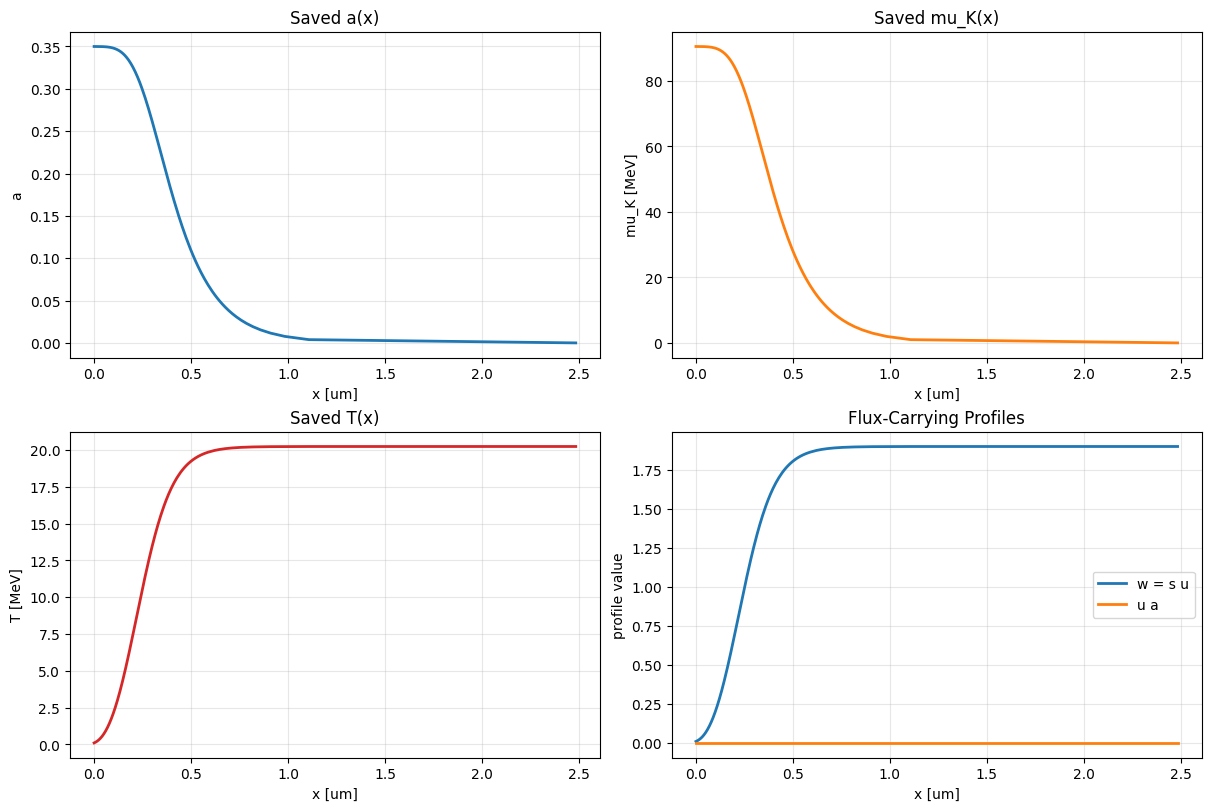

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)

axes[0, 0].plot(x_plot, a, lw=2)
axes[0, 0].set_title("Saved a(x)")
axes[0, 0].set_xlabel(x_plot_label)
axes[0, 0].set_ylabel("a")

axes[0, 1].plot(x_plot, muK, lw=2, color="tab:orange")
axes[0, 1].set_title("Saved mu_K(x)")
axes[0, 1].set_xlabel(x_plot_label)
axes[0, 1].set_ylabel("mu_K [MeV]")

axes[1, 0].plot(x_plot, T_profile, lw=2, color="tab:red")
axes[1, 0].set_title("Saved T(x)")
axes[1, 0].set_xlabel(x_plot_label)
axes[1, 0].set_ylabel("T [MeV]")

axes[1, 1].plot(x_plot, w, lw=2, label="w = s u")
axes[1, 1].plot(x_plot, ua, lw=2, label="u a")
axes[1, 1].set_title("Flux-Carrying Profiles")
axes[1, 1].set_xlabel(x_plot_label)
axes[1, 1].set_ylabel("profile value")
axes[1, 1].legend()

plt.show()

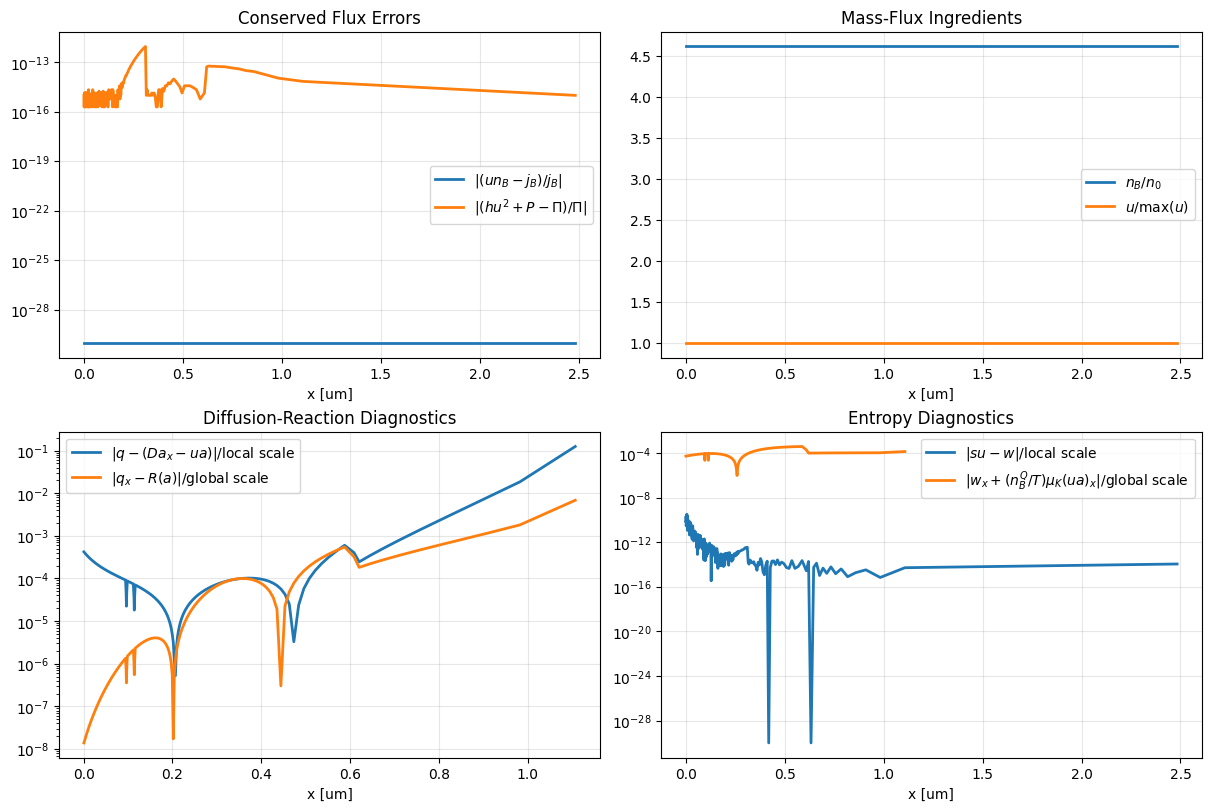

In [5]:
tiny = 1.0e-30
nB_over_n0 = nB / n0

def clipped_abs(values):
    return np.clip(np.abs(np.asarray(values, float)), tiny, None)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)

axes[0, 0].semilogy(x_plot, clipped_abs(mass_rel), lw=2, label=r"$|(u n_B-j_B)/j_B|$")
axes[0, 0].semilogy(x_plot, clipped_abs(momentum_rel), lw=2, label=r"$|(h u^2 + P-\Pi)/\Pi|$")
axes[0, 0].set_title("Conserved Flux Errors")
axes[0, 0].set_xlabel(x_plot_label)
axes[0, 0].legend()

axes[0, 1].plot(x_plot, nB_over_n0, lw=2, label=r"$n_B/n_0$")
axes[0, 1].plot(x_plot, u / np.max(u), lw=2, label=r"$u/\max(u)$")
axes[0, 1].set_title("Mass-Flux Ingredients")
axes[0, 1].set_xlabel(x_plot_label)
axes[0, 1].legend()

axes[1, 0].semilogy(x_mid_plot, clipped_abs(q_closure_rel[interior]), lw=2, label=r"$|q-(D a_x-u a)|$/local scale")
axes[1, 0].semilogy(x_mid_plot, clipped_abs(eq3_residual[interior] / eq3_global_scale), lw=2, label=r"$|q_x-R(a)|$/global scale")
axes[1, 0].set_title("Diffusion-Reaction Diagnostics")
axes[1, 0].set_xlabel(x_plot_label)
axes[1, 0].legend()

axes[1, 1].semilogy(x_plot, clipped_abs(w_closure_rel), lw=2, label=r"$|s u-w|$/local scale")
axes[1, 1].semilogy(x_mid_plot, clipped_abs(eq4_residual[interior] / eq4_global_scale), lw=2, label=r"$|w_x+(n_B^Q/T)\mu_K (u a)_x|$/global scale")
axes[1, 1].set_title("Entropy Diagnostics")
axes[1, 1].set_xlabel(x_plot_label)
axes[1, 1].legend()

plt.show()

In [6]:
if RUN_FRESH_SOLVE:
    fresh = pv.solve_steady_front_entropy_TQguess_uagrad(
        T=T_INPUT,
        nB_N=nB_N_INPUT,
        B_one_forth=BAG_ONE_FORTH,
        aQstar=A_QSTAR,
        ms=MS,
        tail_eps=float(saved["tail_eps"]),
        jB_guess=float(saved["jB"]),
        TQ_guess=float(saved["T_Q"]),
        return_profile=True,
        verb=False,
    )

    compare_keys = [
        "success",
        "jB",
        "T_Q",
        "Pi",
        "lambda",
        "tail_residual_norm",
        "entropy_tail_residual_norm",
    ]

    for key in compare_keys:
        saved_value = saved[key]
        fresh_value = fresh[key]
        if np.isscalar(saved_value) and np.isscalar(fresh_value):
            print(f"{key:<28} saved={saved_value!r:<22} fresh={fresh_value!r}")
        else:
            print(key)
else:
    print(
        "Set RUN_FRESH_SOLVE = True in the setup cell to regenerate the profile with "
        "solve_steady_front_entropy_TQguess_uagrad(...) and compare it directly to the saved dict."
    )

Set RUN_FRESH_SOLVE = True in the setup cell to regenerate the profile with solve_steady_front_entropy_TQguess_uagrad(...) and compare it directly to the saved dict.
